# Churn: Supervised ML and Survival Analysis

**What you'll learn**

- How to frame churn precisely: contractual vs non-contractual, and how to design a
  defensible label with an explicit **as-of date**, **observation window**, and
  **performance window** — plus a simulation showing how the sloppy rule "no purchase in
  30 days = churned" mislabels perfectly healthy customers.
- The supervised pipeline done right: as-of-time snapshot features on a simulated
  subscription business with known churn drivers, LightGBM with **temporal validation**,
  and evaluation that matters in practice — **lift/gains at intervention capacity** and
  **calibration for expected-value math**, not just AUC.
- Why censoring breaks naive lifetime math (demonstrated numerically against ground
  truth), and the survival toolkit that fixes it: Kaplan–Meier by segment, the log-rank
  test, and Cox proportional hazards with hazard ratios you can explain to a PM.
- Per-customer survival curves and expected remaining lifetime — the bridge from churn
  modeling to LTV ([./03_ltv_modeling.ipynb](./03_ltv_modeling.ipynb)).
- When to use which framing: binary-window churn for intervention targeting, survival for
  lifetime and timing questions — and why **risk-based targeting is not effect-based
  targeting** (the uplift lens,
  [../03_causal_inference/05_uplift_cate.ipynb](../03_causal_inference/05_uplift_cate.ipynb)).

**Why it matters in interviews**

- "Build a churn model for us" is a staple end-to-end case for senior DS/AS roles; the
  evaluation is mostly about label design, leakage discipline, and what you'd do with the
  scores — not the classifier.
- Survival analysis questions ("our average customer lifetime is 8 months — do you believe
  it?", "what does a hazard ratio of 1.8 mean?") separate candidates who have shipped
  retention work from those who have only trained classifiers.
- The retention-offer targeting question ("whom do you call?") tests whether you know the
  difference between predicting churn and preventing it.

Everything runs on simulated data with planted ground truth, so every method's output can
be checked against what is actually there.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from lightgbm import LGBMClassifier
from scipy.special import expit
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.isotonic import IsotonicRegression
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test, proportional_hazard_test
from lifelines.utils import restricted_mean_survival_time

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 25)
pd.set_option("display.precision", 4)

## 1. Framing churn precisely

"Predict churn" is underspecified until you answer two questions: *what kind of
relationship is it*, and *what exactly counts as churned, measured when*?

| | **Contractual** | **Non-contractual** |
|---|---|---|
| Examples | SaaS seats, streaming subs, telecom, insurance | e-commerce, marketplaces, ride-hailing, grocery |
| Churn event | **Observable**: cancellation / non-renewal | **Latent**: the customer just… stops. No event exists |
| Natural label | cancel date (still needs a window for "will churn soon") | must be *defined* by an inactivity rule or inferred probabilistically |
| Right tools | binary-window classifier, KM/Cox on cancel times | inactivity labels (carefully), BTYD models (BG/NBD — see [./03_ltv_modeling.ipynb](./03_ltv_modeling.ipynb)) |

### Label anatomy: as-of date, observation window, performance window

A production churn label is always relative to an **as-of date** (the moment you would
score customers in production):

- **Observation window** (history): everything *before* the as-of date. Features may use
  only this.
- **Performance window** (label): a fixed horizon *after* the as-of date. The label reads
  only this: `1` if the customer churns inside it, `0` otherwise.
- **Eligibility**: only customers *active at the as-of date* get a row. Already-churned
  customers and not-yet-signed-up customers are excluded.

The window length is a product decision, not a modeling one: it should match how far in
advance the intervention needs to act (an outreach team needs 30–90 days of warning; a
renewal-pricing model may need 12 months). We make the trade-off concrete in Exercise 1.

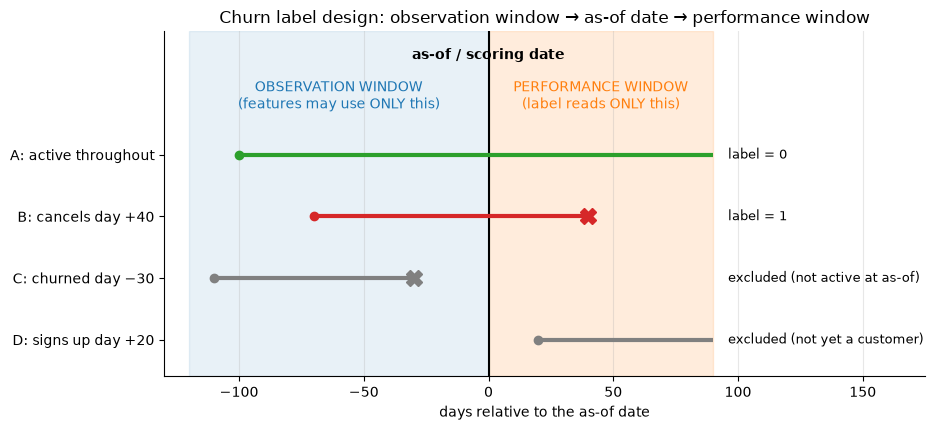

In [2]:
# The label timeline, drawn once so it is unambiguous.
fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.axvspan(-120, 0, color="tab:blue", alpha=0.10)
ax.axvspan(0, 90, color="tab:orange", alpha=0.14)
ax.axvline(0, color="black", lw=1.5)
ax.text(-60, 4.75, "OBSERVATION WINDOW\n(features may use ONLY this)",
        ha="center", fontsize=10, color="tab:blue")
ax.text(45, 4.75, "PERFORMANCE WINDOW\n(label reads ONLY this)",
        ha="center", fontsize=10, color="tab:orange")
ax.text(0, 5.55, "as-of / scoring date", ha="center", fontsize=10, fontweight="bold")

examples = [
    # (name, start, end, churn_marker_x, color, note)
    ("A: active throughout", -100, 90, None, "tab:green", "label = 0"),
    ("B: cancels day +40", -70, 40, 40, "tab:red", "label = 1"),
    ("C: churned day −30", -110, -30, -30, "gray", "excluded (not active at as-of)"),
    ("D: signs up day +20", 20, 90, None, "gray", "excluded (not yet a customer)"),
]
for y, (name, x0, x1, xc, c, note) in zip([4, 3, 2, 1], examples):
    ax.hlines(y, x0, x1, color=c, lw=3)
    ax.plot(x0, y, marker="o", color=c, ms=6)
    if xc is not None:
        ax.plot(xc, y, marker="X", color=c, ms=12)
    ax.text(96, y, note, va="center", fontsize=9)
ax.set_yticks([4, 3, 2, 1], [e[0] for e in examples])
ax.set_xlim(-130, 175)
ax.set_ylim(0.4, 6.0)
ax.set_xlabel("days relative to the as-of date")
ax.set_title("Churn label design: observation window → as-of date → performance window")
ax.grid(axis="y", visible=False)
plt.show()

### Why sloppy labels hurt: "no purchase in 30 days = churned"

In non-contractual settings teams often define churn as *no activity in the last K days*,
with K picked by convention (30, 60, 90). The problem: purchase frequency is wildly
heterogeneous, so a fixed window confuses *slow* with *gone*. We simulate a retail base
where we know the truth — each customer buys as a Poisson process with their own
inter-purchase gap, and some customers genuinely "die" (stop forever) at a known time.
Then we grade the fixed-window rule against the truth.

In [3]:
n_c = 4_000
# Per-customer mean gap between purchases (days): median ~12, long right tail.
mean_gap = rng.lognormal(np.log(12), 0.7, n_c)
death_time = rng.exponential(300, n_c)          # true "gone forever" time (days)
horizon = 365

# Purchase process: first purchase at day 0 (acquisition), exponential gaps after,
# stopped at min(death_time, horizon).
max_purch = 220
gaps = rng.exponential(mean_gap[:, None], (n_c, max_purch))
times = np.cumsum(gaps, axis=1)
alive_end = np.minimum(death_time, horizon)[:, None]
times = np.where(times <= alive_end, times, np.nan)

last_purchase = np.fmax(np.nanmax(times, axis=1), 0.0)   # day of last purchase (0 if none after acq.)
truly_dead = death_time <= horizon

flag_30d = (horizon - last_purchase) > 30                # the sloppy rule
# A per-customer rule: inactive for > 3x their own observed average gap.
obs_gap = np.where(last_purchase > 0,
                   last_purchase / np.maximum(np.sum(~np.isnan(times), axis=1), 1),
                   horizon)                              # avg observed gap (crude but honest)
flag_personal = (horizon - last_purchase) > 3 * obs_gap

lab = pd.DataFrame({
    "mean_gap": mean_gap, "truly_dead": truly_dead,
    "flag_30d": flag_30d, "flag_personal": flag_personal,
})
lab["gap_quintile"] = pd.qcut(lab["mean_gap"], 5, labels=["q1 fastest", "q2", "q3", "q4", "q5 slowest"])

alive = lab[~lab["truly_dead"]]
dead = lab[lab["truly_dead"]]
summary = pd.DataFrame({
    "false churn rate | alive (30d rule)": alive.groupby("gap_quintile", observed=True)["flag_30d"].mean(),
    "false churn rate | alive (personal rule)": alive.groupby("gap_quintile", observed=True)["flag_personal"].mean(),
})
print(summary.round(3).to_string())
print(f"\nOverall, among truly-ALIVE customers:  30d rule flags {alive['flag_30d'].mean():.1%} as churned, "
      f"personal rule {alive['flag_personal'].mean():.1%}")
print(f"Overall, among truly-DEAD customers:   30d rule catches {dead['flag_30d'].mean():.1%}, "
      f"personal rule {dead['flag_personal'].mean():.1%}")

              false churn rate | alive (30d rule)  false churn rate | alive (personal rule)
gap_quintile                                                                               
q1 fastest                                  0.005                                     0.036
q2                                          0.023                                     0.055
q3                                          0.083                                     0.054
q4                                          0.209                                     0.064
q5 slowest                                  0.371                                     0.052

Overall, among truly-ALIVE customers:  30d rule flags 13.5% as churned, personal rule 5.2%
Overall, among truly-DEAD customers:   30d rule catches 97.6%, personal rule 88.4%


/tmp/ipykernel_28756/242766787.py:15: RuntimeWarning: All-NaN slice encountered
  last_purchase = np.fmax(np.nanmax(times, axis=1), 0.0)   # day of last purchase (0 if none after acq.)


The fixed 30-day rule flags a large share of the *slowest-but-alive* quintile as churned —
these are customers whose natural rhythm is a purchase every ~4–8 weeks. Train a model on
these labels and it learns to "predict" purchase infrequency, not churn; run a win-back
campaign against them and your "reactivation rate" looks great because they were never
gone. Scaling the window to each customer's own cadence removes most of the false churn
at a modest cost in catching truly-dead customers slowly.

The principled version of this idea — a probabilistic P(alive) from the customer's
transaction pattern (BG/NBD) — is developed in
[./03_ltv_modeling.ipynb](./03_ltv_modeling.ipynb). The rest of *this* notebook uses a
**contractual** setting, where the churn event is observable and both the supervised and
survival toolkits apply cleanly.

## 2. A simulated subscription business with known ground truth

We simulate 9,000 subscribers of a monthly-billed product, observed for 30 calendar
months with signups spread uniformly across the period (so recent cohorts are heavily
censored, as in real data). Churn is generated by a discrete-time hazard: each month an
active customer churns with probability given by a logistic model of their attributes and
tenure. Because monthly hazards are small, `exp(coef)` in this generator is (to a very
good approximation) the **true hazard ratio** we will later ask Cox regression to recover.

| Driver | Mechanism | True effect |
|---|---|---|
| Onboarding hump | logit +0.85 in months 1–2, +0.35 in month 3 | hazard falls with tenure |
| Paid acquisition (45%) | +log(1.8) | **HR 1.8** vs organic |
| Autopay enabled (50%) | +log(0.65) | **HR 0.65** (protective) |
| Standard plan ($15) | +log(1.15) | HR 1.15 vs basic ($9) |
| Premium plan ($25) | +log(1.6) **in months 1–6 only** | HR 1.6 early → 1.0 after: a planted PH violation |
| Disengagement (35% are "decliners") | usage decays ~13%/month; hazard ramps to HR 2.5 by month 6 | *latent* — visible only through usage |
| Support friction (25% "ticket-prone") | 0.6 tickets/month vs 0.06; HR 1.5 | *latent* — visible only through tickets |

Base monthly hazard for the reference customer (organic, basic, no autopay, engaged,
no tickets, past onboarding) is `expit(-3.55)` ≈ 2.8%/month. The two latent traits matter:
the *causes* of churn are disengagement and friction, but the *observables* are usage
curves and ticket counts — exactly the situation a real feature pipeline faces.

In [4]:
N = 9_000
OBS_M = 30                                    # calendar months observed: 0..29
signup_month = rng.integers(0, OBS_M, N)

plan = rng.choice(["basic", "standard", "premium"], size=N, p=[0.45, 0.35, 0.20])
price = pd.Series(plan).map({"basic": 9.0, "standard": 15.0, "premium": 25.0}).to_numpy()
paid = rng.random(N) < 0.45                  # paid acquisition vs organic
autopay = rng.random(N) < 0.50
decliner = rng.random(N) < 0.35              # latent disengagement trait
support_prone = rng.random(N) < 0.25         # latent friction trait

base_usage = rng.lognormal(np.log(14), 0.5, N) * np.where(plan == "premium", 1.2, 1.0)
decay = np.clip(np.where(decliner, rng.normal(0.87, 0.02, N), rng.normal(1.0, 0.01, N)), 0.75, 1.03)
ticket_rate = np.where(support_prone, 0.6, 0.06)

HR_PAID, HR_AUTOPAY, HR_STD, HR_PREM, HR_DECL, HR_TICK = 1.8, 0.65, 1.15, 1.6, 2.5, 1.5
BASE_LOGIT = -3.55

def monthly_hazard(t):
    """P(churn in tenure month t | active at its start), for all customers."""
    lin = (BASE_LOGIT
           + 0.85 * (t <= 2) + 0.35 * (t == 3)                    # onboarding hump
           + np.log(HR_PAID) * paid
           + np.log(HR_AUTOPAY) * autopay
           + np.log(HR_STD) * (plan == "standard")
           + np.log(HR_PREM) * ((plan == "premium") & (t <= 6))   # early-only: PH violation
           + np.log(HR_DECL) * decliner * min(t / 6, 1.0)         # disengagement ramps up
           + np.log(HR_TICK) * support_prone)
    return expit(lin)

# True (uncensored) lifetime in months, capped at 240 for the rare near-immortal customer.
MAX_M = 240
alive_sim = np.ones(N, bool)
true_lifetime = np.full(N, MAX_M)
for t in range(1, MAX_M + 1):
    h = monthly_hazard(t)
    churn_now = alive_sim & (rng.random(N) < h)
    true_lifetime[churn_now] = t
    alive_sim[churn_now] = False

# What we OBSERVE: censored at the snapshot (calendar month 30).
max_obs = OBS_M - signup_month               # months of possible observation
duration = np.minimum(true_lifetime, max_obs)  # observed months subscribed
event = true_lifetime <= max_obs             # did we see the churn?

print(f"Observed churn events: {event.mean():.1%} of customers "
      f"(the rest are censored — still active at the snapshot)")
print(f"Person-months observed: {duration.sum():,}; "
      f"realized avg monthly churn = {event.sum() / duration.sum():.2%}")
print(f"Median TRUE lifetime (known only because we simulated it): {np.median(true_lifetime):.0f} months")

Observed churn events: 53.6% of customers (the rest are censored — still active at the snapshot)
Person-months observed: 85,349; realized avg monthly churn = 5.65%
Median TRUE lifetime (known only because we simulated it): 12 months


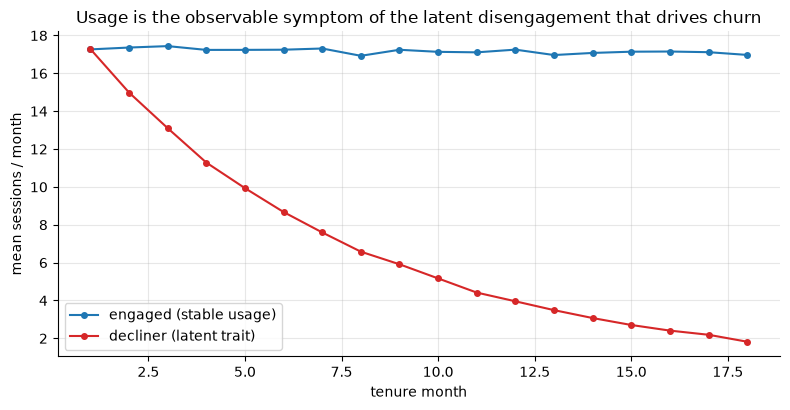

In [5]:
# Monthly usage (sessions) and support tickets, observed only while subscribed.
tgrid = np.arange(1, OBS_M + 1)
obs_mask = tgrid[None, :] <= duration[:, None]
U = base_usage[:, None] * decay[:, None] ** (tgrid - 1)[None, :] * rng.lognormal(0, 0.25, (N, OBS_M))
U[~obs_mask] = np.nan
TK = rng.poisson(np.broadcast_to(ticket_rate[:, None], (N, OBS_M))).astype(float)
TK[~obs_mask] = np.nan

# Cumulative sums for fast windowed features later (NaN treated as 0; we only ever
# read windows that lie fully inside each customer's observed months).
CS_U = np.cumsum(np.nan_to_num(U), axis=1)
CS_T = np.cumsum(np.nan_to_num(TK), axis=1)

fig, ax = plt.subplots()
for trait, label_, c in [(~decliner, "engaged (stable usage)", "tab:blue"),
                         (decliner, "decliner (latent trait)", "tab:red")]:
    with np.errstate(invalid="ignore"):
        prof = np.nanmean(U[trait][:, :18], axis=0)
    ax.plot(tgrid[:18], prof, marker="o", ms=4, color=c, label=label_)
ax.set_xlabel("tenure month")
ax.set_ylabel("mean sessions / month")
ax.set_title("Usage is the observable symptom of the latent disengagement that drives churn")
ax.legend()
plt.show()

## 3. Supervised churn: snapshots, as-of features, temporal validation

The supervised framing asks: *among customers active at the as-of date, who churns within
the next 3 months?* We build **snapshot** datasets: pick an as-of calendar month `a`,
keep customers active at `a`, compute features from months `< a` only, and read the label
from months `a … a+2`. Customers legitimately appear in several snapshots (that is how the
production model will be retrained monthly); what must *never* happen is a feature reading
data at or after its own as-of date.

**Temporal validation**: train on snapshots at months 14/16/18, validate (early stopping,
calibration) on month 21, test on month 24. The test set is strictly later than every
label used in training — the same out-of-time discipline as
[../04_ml_tabular/02_leakage_validation.ipynb](../04_ml_tabular/02_leakage_validation.ipynb).
Random K-fold here would share customers (and calendar time) across folds and flatter the
model.

In [6]:
PLAN_LEVELS = ["basic", "standard", "premium"]

def build_snapshot(a, window=3, leak=False):
    """Snapshot at as-of calendar month `a`: features from months < a, label from a..a+window-1."""
    assert a + window <= OBS_M, "label window must be fully observed"
    tn_all = a - signup_month
    active = (tn_all >= 1) & (duration > tn_all)      # signed up before a, still subscribed at a
    rows = np.where(active)[0]
    t = tn_all[rows]                                   # completed tenure months at as-of

    usage_last = U[rows, t - 1]                        # tenure month t = calendar month a-1
    lo, hi = np.maximum(t - 4, 0), t - 1               # 3 months before the last one
    w = hi - lo
    s3 = CS_U[rows, np.maximum(hi - 1, 0)] - np.where(lo > 0, CS_U[rows, np.maximum(lo - 1, 0)], 0.0)
    usage_prev3 = np.where(w > 0, s3 / np.maximum(w, 1), np.nan)
    usage_trend = usage_last / usage_prev3             # <1 means declining; NaN for month-1 customers

    tlo = np.maximum(t - 3, 0)
    tickets_last3 = CS_T[rows, t - 1] - np.where(tlo > 0, CS_T[rows, np.maximum(tlo - 1, 0)], 0.0)

    X = pd.DataFrame({
        "tenure_m": t,
        "plan": pd.Categorical(plan[rows], categories=PLAN_LEVELS),
        "price": price[rows],
        "paid_channel": paid[rows].astype(int),
        "autopay": autopay[rows].astype(int),
        "usage_last": usage_last,
        "usage_prev3_avg": usage_prev3,
        "usage_trend": usage_trend,
        "tickets_last3": tickets_last3,
    })
    if leak:
        # "months since last active", accidentally computed at label-EXTRACTION time
        # (end of the performance window) instead of the as-of date. 0 for survivors,
        # positive for most churners: it quietly encodes the label.
        X["months_since_active"] = np.maximum(t + window - duration[rows], 0)
    y = ((duration[rows] <= t + window) & event[rows]).astype(int)
    return X, y, rows

train_asofs, valid_asof, test_asof = [14, 16, 18], 21, 24
parts = [build_snapshot(a) for a in train_asofs]
X_tr = pd.concat([p[0] for p in parts], ignore_index=True)
y_tr = np.concatenate([p[1] for p in parts])
X_va, y_va, rows_va = build_snapshot(valid_asof)
X_te, y_te, rows_te = build_snapshot(test_asof)

for name, X, y in [("train (14,16,18)", X_tr, y_tr), ("valid (21)", X_va, y_va), ("test (24)", X_te, y_te)]:
    print(f"{name:>18}: {len(y):5d} active customers, 3-month churn rate = {y.mean():.1%}")

  train (14,16,18):  8919 active customers, 3-month churn rate = 13.3%
        valid (21):  3567 active customers, 3-month churn rate = 14.9%
         test (24):  3773 active customers, 3-month churn rate = 13.4%


In [7]:
FEATS = [c for c in X_tr.columns]
lgbm_params = dict(n_estimators=600, learning_rate=0.05, num_leaves=31,
                   min_child_samples=50, random_state=42, verbosity=-1)

model = LGBMClassifier(**lgbm_params)
model.fit(X_tr[FEATS], y_tr, eval_set=[(X_va[FEATS], y_va)], eval_metric="auc",
          callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)])

p_tr = model.predict_proba(X_tr[FEATS])[:, 1]
p_va = model.predict_proba(X_va[FEATS])[:, 1]
p_te = model.predict_proba(X_te[FEATS])[:, 1]
print(f"AUC  train {roc_auc_score(y_tr, p_tr):.3f} | valid {roc_auc_score(y_va, p_va):.3f} "
      f"| test (out-of-time) {roc_auc_score(y_te, p_te):.3f}")

imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATS).sort_values(ascending=False)
print("\nTop features by LightGBM gain (sanity check, not inference — "
      "see ../04_ml_tabular/05_explainability_shap.ipynb):")
print((imp / imp.sum()).round(3).to_string())

/usr/local/lib/python3.11/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


AUC  train 0.702 | valid 0.582 | test (out-of-time) 0.588

Top features by LightGBM gain (sanity check, not inference — see ../04_ml_tabular/05_explainability_shap.ipynb):
usage_trend        0.279
paid_channel       0.217
usage_prev3_avg    0.147
usage_last         0.125
autopay            0.100
plan               0.058
tenure_m           0.056
tickets_last3      0.016
price              0.002


The model finds the planted structure: usage level/trend (the symptom of latent
disengagement), tenure (the onboarding hump), and tickets do most of the work, with
plan/channel/autopay contributing the rest. An out-of-time AUC in the mid-0.70s is a
realistic ceiling here — churn has irreducible randomness, and the honest features only
see *symptoms* of the latent drivers.

### The leakage failure mode, reproduced

Now the classic accident: a recency feature ("months since last active") computed with
`CURRENT_DATE` at label-extraction time instead of the as-of date. It is 0 for almost
every survivor and positive for most churners — a label detector wearing a feature's
clothes. Watch the AUC.

In [8]:
parts_lk = [build_snapshot(a, leak=True) for a in train_asofs]
X_tr_lk = pd.concat([p[0] for p in parts_lk], ignore_index=True)
X_va_lk, _, _ = build_snapshot(valid_asof, leak=True)
X_te_lk, _, _ = build_snapshot(test_asof, leak=True)

leak_model = LGBMClassifier(**lgbm_params)
leak_model.fit(X_tr_lk, y_tr, eval_set=[(X_va_lk, y_va)], eval_metric="auc",
               callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)])
p_te_lk = leak_model.predict_proba(X_te_lk)[:, 1]
print(f"Honest model  test AUC: {roc_auc_score(y_te, p_te):.3f}")
print(f"Leaky model   test AUC: {roc_auc_score(y_te, p_te_lk):.3f}   <- too good to be true")

/usr/local/lib/python3.11/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Honest model  test AUC: 0.588
Leaky model   test AUC: 0.847   <- too good to be true


The leak even "validates": it inflates *both* the backtest and the out-of-time test,
because the extraction-time join contaminates every historical snapshot the same way. It
dies only in production, where the future is genuinely unavailable and the feature is 0
for everyone. **A churn AUC above ~0.9 is a leakage alarm, not a victory.** The audit
discipline (feature timestamps ≤ as-of, point-in-time joins) is developed in
[../04_ml_tabular/02_leakage_validation.ipynb](../04_ml_tabular/02_leakage_validation.ipynb).

### Evaluate at intervention capacity: lift and gains, not just AUC

The retention team can call perhaps 10% of the base. What matters is how many of the
eventual churners are concentrated in the top of the score ranking — **precision@k** and
**lift@k** — not the global ranking quality across all thresholds.

 targeted    n  churners caught  capture rate  precision  lift
     0.05  189               41         0.081      0.217 1.618
     0.10  377               72         0.142      0.191 1.424
     0.20  755              147         0.291      0.195 1.452
     0.30 1132              212         0.419      0.187 1.396

At 10% capacity - model: 14.2% of churners captured (lift 1.42x); 'steepest usage decline' heuristic: 11.7% (lift 1.17x)


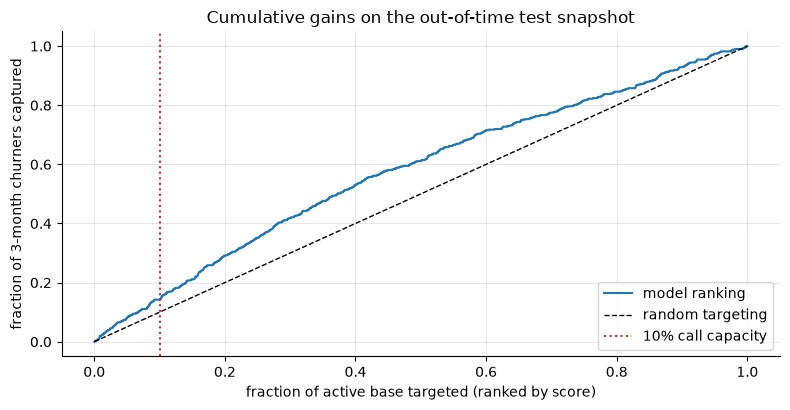

In [9]:
def topk_table(y, p, fracs=(0.05, 0.10, 0.20, 0.30)):
    y = np.asarray(y)
    order = np.argsort(-p, kind="stable")
    rows = []
    for f in fracs:
        n = int(round(f * len(y)))
        cap = y[order[:n]].sum()
        rows.append({"targeted": f, "n": n, "churners caught": int(cap),
                     "capture rate": cap / y.sum(), "precision": cap / n,
                     "lift": (cap / n) / y.mean()})
    return pd.DataFrame(rows)

tk = topk_table(y_te, p_te)
print(tk.round(3).to_string(index=False))

# a sensible non-ML heuristic for comparison: target the steepest usage decline
heur = -np.nan_to_num(X_te["usage_trend"], nan=1.0)
tk_h = topk_table(y_te, heur, fracs=(0.10,))
print(f"\nAt 10% capacity - model: {tk['capture rate'][1]:.1%} of churners captured "
      f"(lift {tk['lift'][1]:.2f}x); 'steepest usage decline' heuristic: "
      f"{tk_h['capture rate'][0]:.1%} (lift {tk_h['lift'][0]:.2f}x)")

order = np.argsort(-p_te, kind="stable")
frac_targeted = np.arange(1, len(y_te) + 1) / len(y_te)
cum_capture = np.cumsum(np.asarray(y_te)[order]) / y_te.sum()
fig, ax = plt.subplots()
ax.plot(frac_targeted, cum_capture, label="model ranking")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random targeting")
ax.axvline(0.10, color="tab:red", ls=":", label="10% call capacity")
ax.set_xlabel("fraction of active base targeted (ranked by score)")
ax.set_ylabel("fraction of 3-month churners captured")
ax.set_title("Cumulative gains on the out-of-time test snapshot")
ax.legend()
plt.show()

### Calibration: the scores must be probabilities, because money math needs them

Targeting decisions are expected-value decisions: *offer a $3 incentive that saves ~30% of
would-be churners, each worth ~$60 of remaining margin*. That math —
`EV(target i) = p_i x 0.30 x $60 − $3` — is only valid if `p_i` is an honest probability.
A model can rank perfectly and still be uncalibrated. We check the reliability curve, fit
isotonic regression on the *validation* snapshot (never the test), and run the economics.
Threshold economics in general: [../04_ml_tabular/03_evaluation_calibration.ipynb](../04_ml_tabular/03_evaluation_calibration.ipynb).

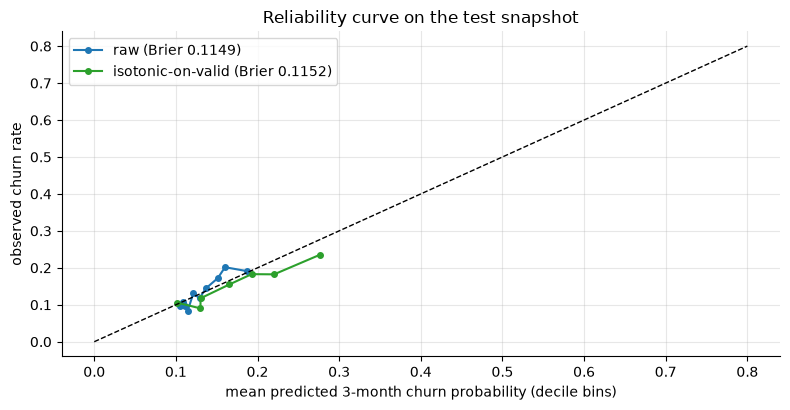

In [10]:
iso = IsotonicRegression(out_of_bounds="clip")
iso.fit(p_va, y_va)
p_te_cal = iso.predict(p_te)

def reliability(y, p, bins=10):
    df = pd.DataFrame({"y": np.asarray(y), "p": p})
    df["bin"] = pd.qcut(df["p"], bins, duplicates="drop")
    g = df.groupby("bin", observed=True).agg(mean_p=("p", "mean"), obs_rate=("y", "mean"), n=("y", "size"))
    return g

fig, ax = plt.subplots()
for pp, lab_, c in [(p_te, f"raw (Brier {brier_score_loss(y_te, p_te):.4f})", "tab:blue"),
                    (p_te_cal, f"isotonic-on-valid (Brier {brier_score_loss(y_te, p_te_cal):.4f})", "tab:green")]:
    g = reliability(y_te, pp)
    ax.plot(g["mean_p"], g["obs_rate"], marker="o", ms=4, color=c, label=lab_)
ax.plot([0, 0.8], [0, 0.8], "k--", lw=1)
ax.set_xlabel("mean predicted 3-month churn probability (decile bins)")
ax.set_ylabel("observed churn rate")
ax.set_title("Reliability curve on the test snapshot")
ax.legend()
plt.show()

In [11]:
V_SAVED, SAVE_RATE, OFFER_COST = 60.0, 0.30, 3.0
p_star = OFFER_COST / (SAVE_RATE * V_SAVED)
print(f"Break-even churn probability p* = cost / (save_rate x value) = {p_star:.3f}\n")

rows = []
order = np.argsort(-p_te_cal, kind="stable")
y_arr = np.asarray(y_te)
for f in [0.02, 0.05, 0.10, 0.20, 0.30, 0.50]:
    n = int(round(f * len(y_arr)))
    sel = order[:n]
    ev = SAVE_RATE * V_SAVED * y_arr[sel].sum() - OFFER_COST * n
    rows.append({"targeted": f, "n": n, "min p targeted": p_te_cal[sel].min(),
                 "total EV ($)": ev, "EV per offer ($)": ev / n})
ev_df = pd.DataFrame(rows)
print(ev_df.round(3).to_string(index=False))

sel_thr = p_te_cal > p_star
ev_thr = SAVE_RATE * V_SAVED * y_arr[sel_thr].sum() - OFFER_COST * sel_thr.sum()
print(f"\nThreshold rule (target all with calibrated p > {p_star:.3f}): "
      f"n = {sel_thr.sum()} ({sel_thr.mean():.0%} of base), total EV = ${ev_thr:,.0f}")

Break-even churn probability p* = cost / (save_rate x value) = 0.167

 targeted    n  min p targeted  total EV ($)  EV per offer ($)
     0.02   75           0.260         117.0             1.560
     0.05  189           0.221         171.0             0.905
     0.10  377           0.221         237.0             0.629
     0.20  755           0.194         399.0             0.528
     0.30 1132           0.167         402.0             0.355
     0.50 1886           0.130        -294.0            -0.156

Threshold rule (target all with calibrated p > 0.167): n = 995 (26% of base), total EV = $399


Expected value per offer falls as capacity grows and eventually goes negative — the
economically optimal budget is where the *marginal* targeted customer crosses `p*`, which
is exactly the threshold rule. None of this arithmetic is possible with an uncalibrated
score: "the model output for this customer is 0.35" must *mean* 35%. (The constant
`SAVE_RATE` hides a stronger assumption — that the offer works equally well on everyone.
Section 6 dismantles that.)

## 4. The survival framing: lifetimes, censoring, hazards

The classifier answers "who churns in the next 3 months?". It cannot answer "how long
does a customer live?", "when is churn risk highest?", or "how many months of revenue
remain in this cohort?" — those are *time-to-event* questions, and the central obstacle
is **censoring**: at any snapshot, most customers haven't churned *yet*. Their lifetimes
are not missing — they are partially observed (`lifetime > tenure so far`), and both
discarding them and treating them as churned is wrong.

### Censoring bias, measured against ground truth

Because we simulated the business, we know every customer's true lifetime — including the
future the snapshot cannot see. Compare three estimates of "average lifetime over the
first 30 months" (the restricted mean, so all numbers are on the same footing):

In [12]:
kmf = KaplanMeierFitter()
kmf.fit(duration, event, label="all customers")

truth_rm30 = np.minimum(true_lifetime, 30).mean()
naive_churned = duration[event].mean()
naive_all = duration.mean()
km_rm30 = restricted_mean_survival_time(kmf, t=30)

comp = pd.DataFrame({
    "estimate of mean lifetime, first 30 months": [
        "TRUTH (from the simulator's uncensored lifetimes)",
        "naive: average over CHURNED customers only",
        "naive: all observed durations (censored treated as churned)",
        "Kaplan-Meier restricted mean, RMST(30)"],
    "months": [truth_rm30, naive_churned, naive_all, km_rm30],
})
comp["bias vs truth"] = comp["months"] / truth_rm30 - 1
print(comp.round(2).to_string(index=False))
print(f"\nKM median lifetime: {kmf.median_survival_time_:.0f} months "
      f"(true median: {np.median(true_lifetime):.0f})")

                 estimate of mean lifetime, first 30 months  months  bias vs truth
          TRUTH (from the simulator's uncensored lifetimes)   14.84           0.00
                 naive: average over CHURNED customers only    6.93          -0.53
naive: all observed durations (censored treated as churned)    9.48          -0.36
                     Kaplan-Meier restricted mean, RMST(30)   14.86           0.00

KM median lifetime: 12 months (true median: 12)


The churned-only average is biased **low**, badly, for two stacked reasons: (1) it drops
every long-lived customer who hasn't churned yet, and (2) recent cohorts can only
contribute *short* churned lifetimes (a 5-month-old cohort cannot contain a 20-month
churner). This is the number that appears in decks as "our average customer lifetime is
X months" — treat it as an alarm whenever the denominator is "churned customers".
Kaplan–Meier uses the censored customers correctly (they contribute risk-time up to their
censoring month) and lands on the truth.

### Kaplan–Meier by segment and the log-rank test

           organic: KM median lifetime =   17 months, RMST(30) = 17.1 months
  paid acquisition: KM median lifetime =    9 months, RMST(30) = 12.1 months


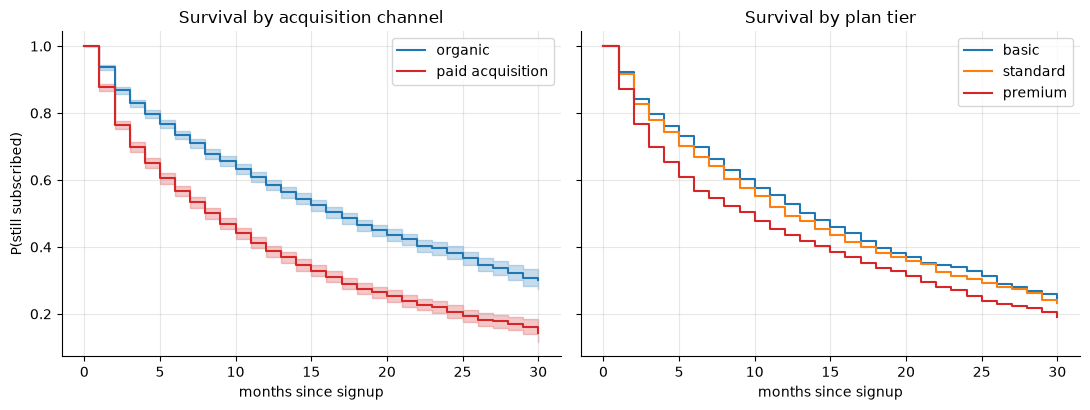


Log-rank test, organic vs paid: statistic = 370.3, p = 1.62e-82


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for seg, mask, c in [("organic", ~paid, "tab:blue"), ("paid acquisition", paid, "tab:red")]:
    km = KaplanMeierFitter().fit(duration[mask], event[mask], label=seg)
    km.plot_survival_function(ax=axes[0], color=c)
    print(f"{seg:>18}: KM median lifetime = {km.median_survival_time_:>4.0f} months, "
          f"RMST(30) = {restricted_mean_survival_time(km, t=30):.1f} months")
axes[0].set_title("Survival by acquisition channel")

for seg, c in [("basic", "tab:blue"), ("standard", "tab:orange"), ("premium", "tab:red")]:
    mask = plan == seg
    km = KaplanMeierFitter().fit(duration[mask], event[mask], label=seg)
    km.plot_survival_function(ax=axes[1], color=c, ci_show=False)
axes[1].set_title("Survival by plan tier")
for ax in axes:
    ax.set_xlabel("months since signup")
    ax.set_ylabel("P(still subscribed)")
plt.show()

lr = logrank_test(duration[~paid], duration[paid], event[~paid], event[paid])
print(f"\nLog-rank test, organic vs paid: statistic = {lr.test_statistic:.1f}, p = {lr.p_value:.2e}")

Two things worth narrating in an interview:

- Every curve shows the **onboarding cliff** (steep drop in months 1–3) then flattens —
  retention risk is front-loaded, so onboarding interventions have the most room.
- The premium curve separates from basic early and then runs *parallel* after ~month 6 —
  visually consistent with the planted early-only price-shock effect. KM curves by segment
  are descriptive, though: they don't adjust for anything else. For adjusted, quantified
  effects we move to Cox.

### Cox proportional hazards: effect sizes on the hazard scale

The Cox model leaves the baseline hazard shape free (it absorbs the onboarding hump) and
estimates multiplicative covariate effects — hazard ratios. We fit on the covariates
known at signup and compare against the planted truth.

In [14]:
cox_df = pd.DataFrame({
    "duration_m": duration, "churned": event.astype(int),
    "paid_channel": paid.astype(int), "autopay": autopay.astype(int),
    "plan_standard": (plan == "standard").astype(int),
    "plan_premium": (plan == "premium").astype(int),
})
cph = CoxPHFitter()
cph.fit(cox_df, duration_col="duration_m", event_col="churned")

summ = cph.summary[["coef", "exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].copy()
summ["true HR"] = [1.8, 0.65, 1.15, "1.6 (months 1-6) then 1.0"]
print(summ.round(3).to_string())

                coef  exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p                    true HR
covariate                                                                                                  
paid_channel   0.569      1.766                1.669                1.869  0.000                        1.8
autopay       -0.387      0.679                0.642                0.719  0.000                       0.65
plan_standard  0.063      1.065                0.998                1.136  0.058                       1.15
plan_premium   0.276      1.318                1.225                1.419  0.000  1.6 (months 1-6) then 1.0


Reading the table like a senior candidate:

- **Paid channel and autopay are recovered close to truth** (true 1.8 and 0.65). The point
  estimates sit slightly *toward 1* — that is not a bug. Two latent traits (decliner,
  ticket-prone) are omitted, and unlike OLS, omitting even *independent* covariates
  attenuates Cox HRs: high-frailty customers die out of the risk set early, so the
  surviving groups become progressively more selected. Hazard ratios are
  **non-collapsible**; marginal and conditional HRs differ. Know this nuance — it also
  explains why HRs from different covariate sets aren't comparable.
- **Premium** shows an HR between its early truth (1.6) and late truth (1.0) — a
  time-averaged compromise, which is exactly what Cox reports when the effect is not
  proportional. The PH check should catch it:

In [15]:
ph = proportional_hazard_test(cph, cox_df, time_transform="rank")
print(ph.summary.round(4).to_string())
print("\nPH assumption: small p = evidence the covariate's effect CHANGES with tenure.")

               test_statistic       p  -log2(p)
autopay                3.4467  0.0634    3.9799
paid_channel           8.8024  0.0030    8.3768
plan_premium          26.2927  0.0000   21.7006
plan_standard          1.9875  0.1586    2.6565

PH assumption: small p = evidence the covariate's effect CHANGES with tenure.


`plan_premium` fails the test decisively — as planted (its effect exists only in months
1–6). In practice you would respond by stratifying on plan, adding a
time-interaction (`premium x log(t)`), or fitting piecewise effects; and you would
*report* it as "premium churn is an early-tenure price-shock problem", which is a
different business action than "premium churns more". The mild signal on other covariates
is the frailty selection effect above eroding proportionality slowly — with n = 9,000 the
test has power to notice. A PH violation changes *interpretation* (time-averaged HR),
not necessarily *prediction quality*; act on it when the story or the extrapolation
depends on it.

### Hazard ratios in business language

For the PM: "paid-acquired subscribers cancel at ~1.7–1.8x the monthly rate of otherwise
identical organic subscribers, *at every point in their lifecycle*". Concretely, the KM
medians above show organic customers lasting roughly twice as long. What an HR of 1.8 is
**not**: "1.8x as many will ever churn" (eventually everyone can churn) and not "their
lifetime is exactly 1/1.8 as long" (that conversion is exact only for constant hazards).
The honest translation is always through the survival curves: medians, RMST, or
"P(still here at 12 months)".

## 5. Per-customer curves, expected remaining lifetime, and the LTV bridge

`predict_survival_function` gives each customer their own curve. Three personas:

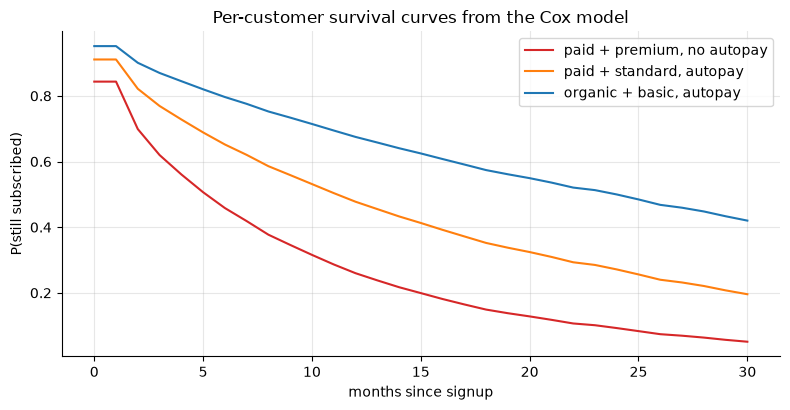

In [16]:
personas = pd.DataFrame({
    "paid_channel": [1, 1, 0], "autopay": [0, 1, 1],
    "plan_standard": [0, 1, 0], "plan_premium": [1, 0, 0],
}, index=["paid + premium, no autopay", "paid + standard, autopay", "organic + basic, autopay"])

times = np.arange(0, 31)
sf = cph.predict_survival_function(personas, times=times)
fig, ax = plt.subplots()
for col, c in zip(sf.columns, ["tab:red", "tab:orange", "tab:blue"]):
    ax.plot(sf.index, sf[col], color=c, label=col)
ax.set_xlabel("months since signup")
ax.set_ylabel("P(still subscribed)")
ax.set_title("Per-customer survival curves from the Cox model")
ax.legend()
plt.show()

**Expected remaining lifetime** conditions on being alive today: for a customer at tenure
$t_0$, $S_c(u) = S(t_0+u)/S(t_0)$, and expected months retained over the next $H$ is
$\sum_{u=1}^{H} S_c(u)$. Two practical notes:

- Conditioning matters: surviving the onboarding cliff is *good news*, so expected
  remaining lifetime **rises** with early tenure.
- Our data supports 30 months; we cap the horizon so $t_0 + H \le 30$. Beyond the observed
  support, KM/Cox curves are flat by construction — extrapolating them is a silent lie.
  Parametric survival or BTYD models (which make explicit shape assumptions) handle
  longer horizons: [./03_ltv_modeling.ipynb](./03_ltv_modeling.ipynb).

In [17]:
S = sf.to_numpy()          # rows = months 0..30, cols = personas
H = 12
rows = []
for j, name in enumerate(sf.columns):
    for t0 in (3, 12):
        er = S[t0 + 1: t0 + 1 + H, j].sum() / S[t0, j]
        rows.append({"persona": name, "tenure today": t0, f"expected months retained (next {H})": er})
er_df = pd.DataFrame(rows).pivot(index="persona", columns="tenure today",
                                 values=f"expected months retained (next {H})")
print(er_df.round(2).to_string())

tenure today                   3      12
persona                                 
organic + basic, autopay    10.04  10.19
paid + premium, no autopay   6.75   7.06
paid + standard, autopay     8.64   8.87


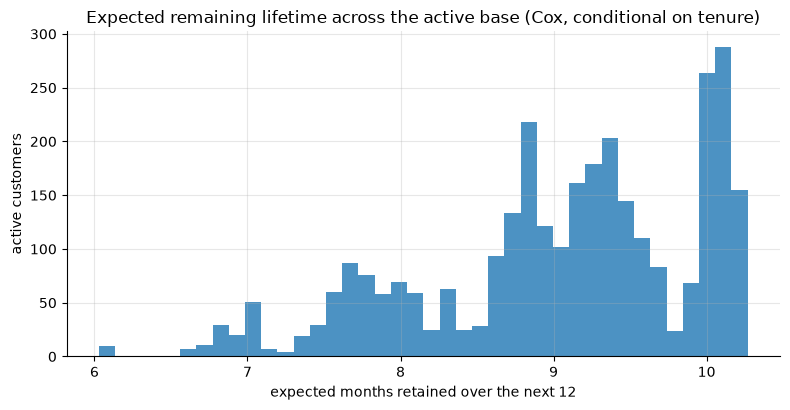

Active customers scored: 3,084
Mean expected months retained (next 12): 9.0
Expected gross margin from this base over the next 12 months: $270,096
Discounting, longer horizons, and purchase-frequency LTV: see ./03_ltv_modeling.ipynb


In [18]:
# Same computation for every currently-active customer -> the LTV input.
active_now = np.where(~event)[0]
active_now = active_now[(duration[active_now] >= 1) & (duration[active_now] <= 18)]  # keep t0+H <= 30
Xact = cox_df.loc[active_now, ["paid_channel", "autopay", "plan_standard", "plan_premium"]]
S_all = cph.predict_survival_function(Xact, times=times).to_numpy()

t0s = duration[active_now]
er_months = np.empty(len(active_now))
for t0 in np.unique(t0s):
    m = t0s == t0
    er_months[m] = S_all[t0 + 1: t0 + 1 + H, m].sum(axis=0) / S_all[t0, m]

margin_next12 = er_months * 0.7 * price[active_now]     # 70% gross margin on the monthly price
fig, ax = plt.subplots()
ax.hist(er_months, bins=40, color="tab:blue", alpha=0.8)
ax.set_xlabel(f"expected months retained over the next {H}")
ax.set_ylabel("active customers")
ax.set_title("Expected remaining lifetime across the active base (Cox, conditional on tenure)")
plt.show()
print(f"Active customers scored: {len(active_now):,}")
print(f"Mean expected months retained (next 12): {er_months.mean():.1f}")
print(f"Expected gross margin from this base over the next 12 months: ${margin_next12.sum():,.0f}")
print("Discounting, longer horizons, and purchase-frequency LTV: see ./03_ltv_modeling.ipynb")

This is the survival→LTV bridge: expected remaining months x margin per month (plus
discounting) *is* the remaining-lifetime-value of the current base, and it updates
per-customer as tenure and covariates change. The classifier's 3-month probability cannot
produce this number.

## Which framing when

| Question | Framing | Why |
|---|---|---|
| Who should the retention team contact this month? | **Binary window** (+ calibration, top-k) | Fixed horizon matches the intervention cadence; scores feed a ranked queue |
| What is this cohort worth? How many months remain? | **Survival** | Needs the whole time axis and correct censoring handling |
| When in the lifecycle is risk concentrated? | **Survival** (hazard shape) | The hazard curve *is* the answer (onboarding cliff, renewal spikes) |
| Did feature X change how long customers stay? | **Survival** (log-rank / Cox, ideally on experiment data) | "Longer" is a time-to-event claim, not a 30-day binary |
| Non-contractual "is this customer still alive?" | **BTYD / P(alive)** | No churn event exists to classify or time |

They are complements, not competitors: a common production stack scores a binary-window
model monthly for targeting *and* maintains survival curves for finance/LTV. (A
discrete-time hazard model — logistic regression or GBM on customer-month rows with
tenure as a feature — is the bridge between the two framings: it is both a classifier
and a hazard estimator.)

## 6. Closing the loop: risk-based targeting is not effect-based targeting

Everything above ranks customers by *risk*. But the retention offer only creates value
for customers whose behavior it *changes* — the persuadables. The highest-risk customers
are often the least savable (multi-cause, already disengaged: a $3 coupon does not fix
eight support tickets), and some low-risk customers are best left alone ("sleeping dogs" —
a retention email can *remind* someone to cancel). We plant a savability profile where
persuadables sit just below the top of the risk ranking, and compare targeting rules at
fixed capacity.

In [19]:
p = p_te_cal
q90, q65, q30 = np.quantile(p, [0.90, 0.65, 0.30])
# True per-customer churn reduction if offered (unknowable in practice without experiments):
tau = np.where(p >= q90, 0.005,          # lost causes: high risk, unsavable
      np.where(p >= q65, 0.10,           # persuadables: elevated risk, very savable
      np.where(p >= q30, 0.03, 0.01)))   # low risk: little to save

cap = 0.15
n = int(cap * len(p))
saved_risk = tau[np.argsort(-p, kind="stable")[:n]].sum()
saved_uplift = tau[np.argsort(-tau, kind="stable")[:n]].sum()
print(f"Capacity: {n} offers ({cap:.0%} of the active base)")
print(f"Expected churners saved, targeting by RISK:  {saved_risk:6.1f} "
      f"({1000 * saved_risk / n:.0f} per 1,000 offers)")
print(f"Expected churners saved, targeting by UPLIFT: {saved_uplift:6.1f} "
      f"({1000 * saved_uplift / n:.0f} per 1,000 offers)")
print(f"Uplift targeting saves {saved_uplift / saved_risk:.1f}x as many customers "
      f"at the same cost.")

Capacity: 565 offers (15% of the active base)
Expected churners saved, targeting by RISK:    12.3 (22 per 1,000 offers)
Expected churners saved, targeting by UPLIFT:   56.5 (100 per 1,000 offers)
Uplift targeting saves 4.6x as many customers at the same cost.


Risk targeting spends most of the budget on the unsavable top decile; uplift targeting
skips them and harvests the persuadable band. The catch: `tau` is never observed
per-customer. You estimate it with randomized experiments (hold out a control group from
every campaign — non-negotiable) and uplift/CATE models:
[../03_causal_inference/05_uplift_cate.ipynb](../03_causal_inference/05_uplift_cate.ipynb).
The mature pipeline is: churn model to define the *eligible* population and the value at
stake, uplift model (trained on experiment data) to decide *whom* to treat, and calibrated
probabilities to price the whole program.

## 7. Pitfalls

The first three were demonstrated above; the fourth is demonstrated below.

1. **Fixed inactivity windows in non-contractual churn** (§1): mislabels slow-cadence
   customers as churned; the model learns purchase frequency, win-back metrics
   self-congratulate.
2. **Extraction-time features / as-of violations** (§3): recency-style features joined at
   the wrong date encode the label; AUC ~0.9+ on churn is an alarm.
   Full treatment: [../04_ml_tabular/02_leakage_validation.ipynb](../04_ml_tabular/02_leakage_validation.ipynb).
3. **Lifetime math on churned customers only** (§4): biased low by censoring + cohort
   length bias; also its cousin "mean lifetime = 1/churn-rate", which assumes a constant
   hazard that the onboarding cliff plainly violates.
4. **Immortal-time / conditioning bias**: requiring history for features (e.g. "3 full
   months of usage") and then measuring survival **from signup** on that filtered
   population. Everyone in the sample is guaranteed to survive 3 months — the curve is
   inflated by construction. Fix: measure time from the *landmark* (end of month 3),
   conditioning explicitly.
5. **Extrapolating KM/Cox beyond observed follow-up** (§5): the curves go flat because
   the data ends, not because churn stops. Use parametric/BTYD models for long horizons.
6. **Treating risk scores as targeting policy** (§6): the top of the risk ranking is
   rich in lost causes; value comes from persuadables, which only experiments reveal.

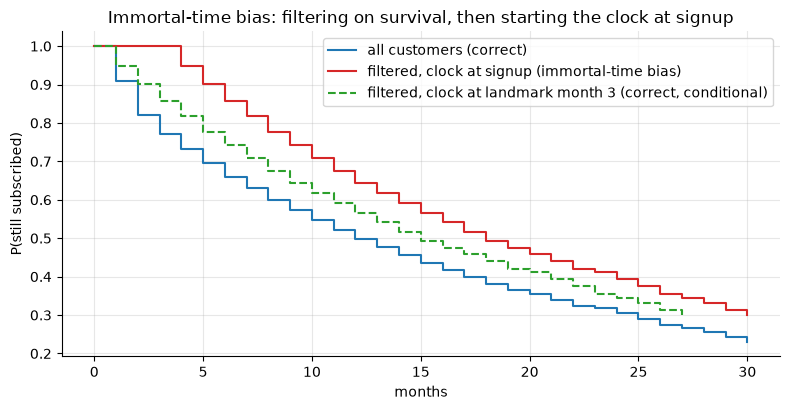

RMST(24) - all customers:                 13.2 months
RMST(24) - filtered, clock at signup:     16.6 months  <- inflated
RMST(24) - filtered, clock at landmark:   14.7 months  (answers a conditional question)


In [20]:
# Pitfall 4 demonstrated: condition on >=3 months of history, measure from signup anyway.
mask_hist = duration >= 4          # "customers with 3 full months of usage history"
km_all = KaplanMeierFitter().fit(duration, event, label="all customers (correct)")
km_bad = KaplanMeierFitter().fit(duration[mask_hist], event[mask_hist],
                                 label="filtered, clock at signup (immortal-time bias)")
km_fix = KaplanMeierFitter().fit(duration[mask_hist] - 3, event[mask_hist],
                                 label="filtered, clock at landmark month 3 (correct, conditional)")

fig, ax = plt.subplots()
km_all.plot_survival_function(ax=ax, ci_show=False, color="tab:blue")
km_bad.plot_survival_function(ax=ax, ci_show=False, color="tab:red")
km_fix.plot_survival_function(ax=ax, ci_show=False, color="tab:green", linestyle="--")
ax.set_xlabel("months")
ax.set_ylabel("P(still subscribed)")
ax.set_title("Immortal-time bias: filtering on survival, then starting the clock at signup")
ax.legend()
plt.show()
print(f"RMST(24) - all customers:                 {restricted_mean_survival_time(km_all, 24):.1f} months")
print(f"RMST(24) - filtered, clock at signup:     {restricted_mean_survival_time(km_bad, 24):.1f} months  <- inflated")
print(f"RMST(24) - filtered, clock at landmark:   {restricted_mean_survival_time(km_fix, 24):.1f} months  (answers a conditional question)")

## Interview corner

**1. "Walk me through building a churn model end-to-end."**
Strong answer, in order: (i) *frame it* — contractual or not, what intervention will
consume the scores, which horizon matches it; (ii) *label design* — as-of dates,
eligibility (active at as-of), performance window; state the mislabeling risk if
non-contractual; (iii) *features* — strictly point-in-time (tenure, usage level & trend,
support contacts, plan/billing), snapshot construction, no extraction-time joins;
(iv) *validation* — out-of-time test that postdates every training label; (v) *metrics* —
precision/lift at the team's real capacity plus calibration, AUC only as a summary;
(vi) *deployment* — monthly retrain-and-score cadence, monitoring for drift;
(vii) *the loop* — randomized holdout in every campaign, move to uplift targeting.
Mentioning (vii) unprompted is the seniority signal.

**2. "Why is churn label design hard?"**
Because churn is often not an event: in non-contractual products it must be defined, and
fixed inactivity windows mislabel slow-cadence customers (show the quintile table from
§1 in words). Even in contractual products you must pick the window to match the
intervention lead time, handle censoring at the snapshot edge, keep involuntary churn
(card failures) separate from voluntary, and avoid seasonal windows that make labels
incomparable across snapshots.

**3. "The Cox model says hazard ratio 1.8 for paid-acquired users. Explain it to a PM."**
"At any point in their lifecycle, a paid-acquired customer who is still with us is ~80%
more likely to cancel *this month* than an identical organic customer." Then convert to
curves, because PMs think in lifetimes: "that compounds to roughly half the median
lifetime — about 9 vs 19 months here." Flag what it is *not*: not "1.8x as many ever
churn", not exactly "lifetime/1.8", and it assumes the ratio is constant over tenure —
which we test (our premium tier failed that test and turned out to be an early-tenure
price-shock story).

**4. "Whom do you target with the retention offer?"**
Not simply the riskiest. Value per offer is `p x save_rate x value − cost`, so calibrated
probabilities set the *eligible* set and budget; but `save_rate` varies — the top of the
risk ranking is dense in lost causes and the bottom holds sleeping dogs. Target estimated
*uplift* at capacity, learned from randomized campaign data with a permanent control
group. If no experiment data exists yet: run the first campaign randomized *within* the
risk-eligible band to bootstrap the uplift model.

**5. "Your churn model shows AUC 0.93. Reaction?"**
Suspicion, not celebration. Churn at useful horizons is mostly not that predictable.
First check for leakage: features computed after the as-of date (recency at extraction
time, post-cancellation flags, billing-status fields that update on churn), label
proxies, and eligibility bugs (scoring already-churned users). Then check the
validation design (random K-fold over customer-months shares customers across folds).
Our planted extraction-time recency feature pushed test AUC from ~0.75 to ~0.95 while
validating cleanly — the backtest cannot save you if every snapshot shares the bug.

**6. "Finance says average customer lifetime is 8 months: total months lived by churned
customers / number of churned customers. Do you believe it?"**
No — it ignores every still-active customer (censoring) and recent cohorts can only
contribute short lifetimes, so it is biased low, potentially by 2x (we measured ~45%
understatement in simulation). Estimate KM and report RMST over a stated horizon, or a
parametric/BTYD extrapolation with assumptions on the table.

**7. "Binary churn model vs survival model — how do you choose?"**
Choose by question: fixed-horizon intervention targeting → binary window (simpler,
calibratable, plugs into capacity math). Lifetime, timing, cohort-value, or
"did X extend retention" questions → survival (censoring-correct, whole time axis).
Note the bridge: a discrete-time hazard model on customer-month rows is both. Bonus
points for saying the two must *agree*: the survival curve integrated over the next 90
days is a 90-day churn probability.

## Key takeaways

- Churn framing precedes modeling: contractual vs non-contractual decides whether churn
  is an event or a definition, and sloppy inactivity labels teach models purchase
  frequency instead of churn.
- A churn label is a triple: eligibility at an as-of date, features from before it,
  outcome from a fixed window after it. Every feature must be computable at the as-of
  moment — validate out-of-time.
- Evaluate against the intervention: lift/precision at the team's capacity and calibrated
  probabilities for EV math. AUC alone answers no business question; AUC ≳ 0.9 on churn
  usually means leakage.
- Censoring is information, not missingness: churned-only lifetime averages are badly
  biased low (we measured ~45% in simulation); KM/RMST recover the truth.
- Hazard ratios are rate multipliers at a point in time ("80% more likely to cancel this
  month"), not lifetime or share-of-churners multipliers; translate via medians/RMST.
  Check PH before telling a time-constant story; violations are often the finding.
- Cox HRs are non-collapsible: omitted (even independent) heterogeneity attenuates them;
  don't compare HRs across models with different covariates.
- Expected remaining lifetime = conditional survival summed over a horizon; times margin,
  it is the LTV input. Don't read it past the observed follow-up.
- Risk ranking finds who *would* churn; only uplift finds who can be *saved*. Keep a
  randomized control in every retention campaign, forever.

## Exercises

**Exercise 1 — label window sensitivity.** Rebuild the snapshots with 1-month and 6-month
performance windows (same as-of months) and retrain the LightGBM. Compare base rates,
out-of-time AUC, and precision@10%. Why does the short window look worse on precision
even if AUC holds up, and what operational constraint does the long window violate?

**Exercise 2 — first-year months by plan.** Using Kaplan–Meier per plan tier, compute
RMST(12) — expected subscribed months in the first year per signup — and turn it into
expected first-year gross margin per signup (70% margin on the monthly price). Which tier
is worth the most at acquisition time?

**Exercise 3 — the autopay 'lever'.** Use the Cox model to compute how many additional
expected months RMST(24) an autopay customer keeps vs an identical non-autopay customer
(organic, standard plan). Then explain why shipping "nudge everyone onto autopay" on the
strength of this number would be a mistake, and what evidence you would demand first.

In [21]:
# --- Solution 1 ---
res = []
for w in (1, 3, 6):
    pw = [build_snapshot(a, window=w) for a in train_asofs]
    Xw = pd.concat([p_[0] for p_ in pw], ignore_index=True)
    yw = np.concatenate([p_[1] for p_ in pw])
    Xvw, yvw, _ = build_snapshot(valid_asof, window=w)
    Xtw, ytw, _ = build_snapshot(test_asof, window=w)
    mw = LGBMClassifier(**lgbm_params)
    mw.fit(Xw, yw, eval_set=[(Xvw, yvw)], eval_metric="auc",
           callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)])
    ptw = mw.predict_proba(Xtw)[:, 1]
    tkw = topk_table(ytw, ptw, fracs=(0.10,))
    res.append({"window (months)": w, "test churn rate": ytw.mean(),
                "test AUC": roc_auc_score(ytw, ptw),
                "precision@10%": tkw["precision"][0], "lift@10%": tkw["lift"][0]})
print(pd.DataFrame(res).round(3).to_string(index=False))
print("\nShort window: rarer positives -> even a good ranking yields low precision at fixed")
print("capacity, and month-to-month churn is noisier. Long window: more positives and higher")
print("precision, but labels take 6 months to mature -> slower retraining/iteration, and the")
print("'about to churn' signal is diluted with far-future churn the team cannot act on yet.")

/usr/local/lib/python3.11/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/usr/local/lib/python3.11/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/usr/local/lib/python3.11/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


 window (months)  test churn rate  test AUC  precision@10%  lift@10%
               1            0.051     0.592          0.093     1.834
               3            0.134     0.588          0.191     1.424
               6            0.240     0.607          0.353     1.468

Short window: rarer positives -> even a good ranking yields low precision at fixed
capacity, and month-to-month churn is noisier. Long window: more positives and higher
precision, but labels take 6 months to mature -> slower retraining/iteration, and the
'about to churn' signal is diluted with far-future churn the team cannot act on yet.


In [22]:
# --- Solution 2 ---
rows = []
for seg in PLAN_LEVELS:
    mask = plan == seg
    km = KaplanMeierFitter().fit(duration[mask], event[mask])
    rm12 = restricted_mean_survival_time(km, t=12)
    monthly_margin = 0.7 * {"basic": 9.0, "standard": 15.0, "premium": 25.0}[seg]
    rows.append({"plan": seg, "RMST(12) months": rm12, "margin/month ($)": monthly_margin,
                 "expected 1st-year margin per signup ($)": rm12 * monthly_margin})
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("\nPremium keeps fewer months (early price-shock hazard) but its higher margin per month")
print("still makes it the most valuable signup in year 1 - retention and value are different axes.")

    plan  RMST(12) months  margin/month ($)  expected 1st-year margin per signup ($)
   basic             8.78               6.3                                    55.30
standard             8.53              10.5                                    89.52
 premium             7.67              17.5                                   134.28

Premium keeps fewer months (early price-shock hazard) but its higher margin per month
still makes it the most valuable signup in year 1 - retention and value are different axes.


In [23]:
# --- Solution 3 ---
pair = pd.DataFrame({"paid_channel": [0, 0], "autopay": [1, 0],
                     "plan_standard": [1, 1], "plan_premium": [0, 0]},
                    index=["autopay", "no autopay"])
sf_pair = cph.predict_survival_function(pair, times=np.arange(0, 25))
rmst24 = sf_pair.iloc[1:].sum()          # sum S(1..24) = expected months in first 24
delta = rmst24["autopay"] - rmst24["no autopay"]
print(f"RMST(24): autopay {rmst24['autopay']:.1f} vs no-autopay {rmst24['no autopay']:.1f} months")
print(f"Difference: {delta:.1f} months  (~${delta * 0.7 * 15:.0f} of margin at the $15 tier)")
print("\nWhy not ship the nudge on this evidence: autopay is self-selected - customers who")
print("enable it are already more committed, so the HR mixes the feature's effect with who")
print("adopts it. (Here we *know* it is causal because we simulated it; in reality you don't.)")
print("Demand: a randomized encouragement experiment (nudge a random subset toward autopay)")
print("and an IV/ITT analysis - see ../03_causal_inference/04_iv_rdd.ipynb and")
print("../03_causal_inference/01_potential_outcomes_dags.ipynb on good vs bad controls.")

RMST(24): autopay 16.0 vs no-autopay 13.4 months
Difference: 2.6 months  (~$27 of margin at the $15 tier)

Why not ship the nudge on this evidence: autopay is self-selected - customers who
enable it are already more committed, so the HR mixes the feature's effect with who
adopts it. (Here we *know* it is causal because we simulated it; in reality you don't.)
Demand: a randomized encouragement experiment (nudge a random subset toward autopay)
and an IV/ITT analysis - see ../03_causal_inference/04_iv_rdd.ipynb and
../03_causal_inference/01_potential_outcomes_dags.ipynb on good vs bad controls.
